# Quality Control Plotting

In [1]:
here::i_am("Manuscript/01_paper_QC.ipynb")

source(here::here("settings.R"))
source(here::here("utils.R"))

here() starts at /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code



In [2]:
io$basedir

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut"

In [3]:
args = list()
args$meta = file.path(io$basedir, 'results/rna_atac/combined_metadata.txt.gz')

In [4]:
meta = fread(args$meta)

In [5]:
colnames(meta)

[1] "cell"                      "barcode"                  
 [3] "sample"                    "nFeature_RNA"             
 [5] "nCount_RNA"                "mitochondrial_percent_RNA"
 [7] "ribosomal_percent_RNA"     "alias"                    
 [9] "day"                       "genotype"                 
[11] "pass_rnaQC"                "doublet_score"            
[13] "doublet_call"              "celltype"                 
[15] "celltype.score"            "closest.cell"             
[17] "day_celltype"              "celltype_genotype"        
[19] "TSSEnrichment_atac"        "ReadsInTSS_atac"          
[21] "PromoterRatio_atac"        "NucleosomeRatio_atac"     
[23] "nFrags_atac"               "BlacklistRatio_atac"      
[25] "pass_atacQC"

In [6]:
table(meta$genotype, meta$sample, meta$day)

, ,  = D2.5

          
           RBG43471 RBG43472 RBG43473 RBG43474 RBG43475 RBG43476 RBG43477
  Eomes_KO        0        0        0        0        0        0        0
  WT           5032     4740        0        0        0        0        0
          
           RBG43478
  Eomes_KO        0
  WT              0

, ,  = D3

          
           RBG43471 RBG43472 RBG43473 RBG43474 RBG43475 RBG43476 RBG43477
  Eomes_KO        0        0    10450     6383        0        0        0
  WT              0        0        0        0     4548     3475        0
          
           RBG43478
  Eomes_KO        0
  WT              0

, ,  = D4.5

          
           RBG43471 RBG43472 RBG43473 RBG43474 RBG43475 RBG43476 RBG43477
  Eomes_KO        0        0        0        0        0        0     7242
  WT              0        0        0        0        0        0        0
          
           RBG43478
  Eomes_KO        0
  WT           4677


In [7]:
sample_rename = c(
    'RBG43471' = 'D2.5 WT Rep 1',
    'RBG43472' = 'D2.5 WT Rep 2',
    'RBG43473' = 'D3 EOMES KD Rep 1',
    'RBG43474' = 'D3 EOMES KD Rep 2',
    'RBG43475' = 'D3 WT Rep 1',
    'RBG43476' = 'D3 WT Rep 2',
    'RBG43477' = 'D4.5 EOMES KD Rep 1',
    'RBG43478' = 'D4.5 WT Rep 1'
)

sample_colors = c(
    'D2.5 WT Rep 1' = '#000000',
    'D2.5 WT Rep 2' = '#202020',
    'D3 WT Rep 1' = '#414141',
    'D3 WT Rep 2' = '#626262',
    'D3 EOMES KD Rep 1' = '#8B0000',
    'D3 EOMES KD Rep 2' = '#A22426',
    'D4.5 WT Rep 1' = '#828282',
    'D4.5 EOMES KD Rep 1' = '#B9484D'
)

genotype_rename = c(
    'RBG43471' = 'WT',
    'RBG43472' = 'WT',
    'RBG43473' = 'EOMES KD',
    'RBG43474' = 'EOMES KD',
    'RBG43475' = 'WT',
    'RBG43476' = 'WT',
    'RBG43477' = 'EOMES KD',
    'RBG43478' = 'WT'
)

In [8]:
meta = meta %>% copy() %>%
    .[,sample_clean := sample_rename[match(sample, names(sample_rename))]] %>% 
    .[,sample_clean := factor(sample_clean, levels = sample_rename)] %>% 
    .[,genotype_clean := genotype_rename[match(sample, names(genotype_rename))]]

In [9]:
# Define a custom theme
theme = theme(
  # axis.title = element_text(color = 'black', size = 7),
  axis.title = element_blank(),
  axis.text.x = element_text(angle=90, hjust=1, vjust=0.5, size=5, color = 'black'), 
  axis.text = element_text(size=5, color='black'),
  text = element_text(size=5),
  plot.margin = margin(0, 3, 0, 0),  # Adjust the margin around the plot
  plot.title = element_text(size=7, face='plain', hjust=0.5, vjust = -0.5),
  panel.border = element_rect(color='black', linewidth=0.5, fill = NA),
  panel.background = element_blank(),
  panel.grid.major = element_line(color = 'grey95'),
  axis.line = element_blank(),
  axis.ticks = element_line(linewidth=0.25, color = 'black'),
  legend.position = 'none'
)

# Create a list of common geoms
geoms <- list(
  geom_violin(linewidth = 0.1, aes(fill = sample_clean)),
  geom_boxplot(width = 0.2, linewidth = 0.1, outlier.shape = NA, fill = 'white'),
  scale_fill_manual(values = sample_colors) 
)

p_rna_reads = ggplot(meta, aes(sample_clean, log10(nCount_RNA))) + 
    geoms + 
    scale_y_continuous(limits = c(0, log10(max(meta$nCount_RNA))), expand = c(0,0,0.1,0)) + 
    ggtitle('log10(# counts)') + 
    theme

p_rna_genes = ggplot(meta, aes(sample_clean, log10(nFeature_RNA))) + 
    geoms + 
    scale_y_continuous(limits = c(0, log10(max(meta$nFeature_RNA))), expand = c(0,0,0.1,0)) + 
    ggtitle('log10(# genes)') + 
    theme

p_rna_ribo = ggplot(meta, aes(sample_clean, ribosomal_percent_RNA)) + 
    geoms + 
    scale_y_continuous(limits = c(0, 100), expand = c(0,0,0,0)) + 
    ggtitle('% Ribo counts') + 
    theme

p_rna_mito = ggplot(meta, aes(sample_clean, mitochondrial_percent_RNA)) + 
    geoms + 
    scale_y_continuous(limits = c(0, 100), expand = c(0,0,0,0)) + 
    ggtitle('% Mito counts') + 
    theme
p_atac_frags = ggplot(meta, aes(sample_clean, log10(nFrags_atac))) + 
    geoms + 
    scale_y_continuous(limits = c(0, log10(max(meta$nFrags_atac))), expand = c(0,0,0.1,0)) + 
    ggtitle('log10(# Fragments)') + 
    theme

p_atac_tss = ggplot(meta, aes(sample_clean, TSSEnrichment_atac)) + 
    geoms + 
    scale_y_continuous(limits = c(0, max(meta$TSSEnrichment_atac)), expand = c(0,0,0.1,0)) + 
    ggtitle('TSS Enrichment') + 
    theme

options(repr.plot.height=7, repr.plot.width=25)
p1 = ggarrange(p_rna_reads, p_rna_genes, p_rna_mito, p_rna_ribo, p_atac_frags, p_atac_tss, nrow = 1, align = 'hv')


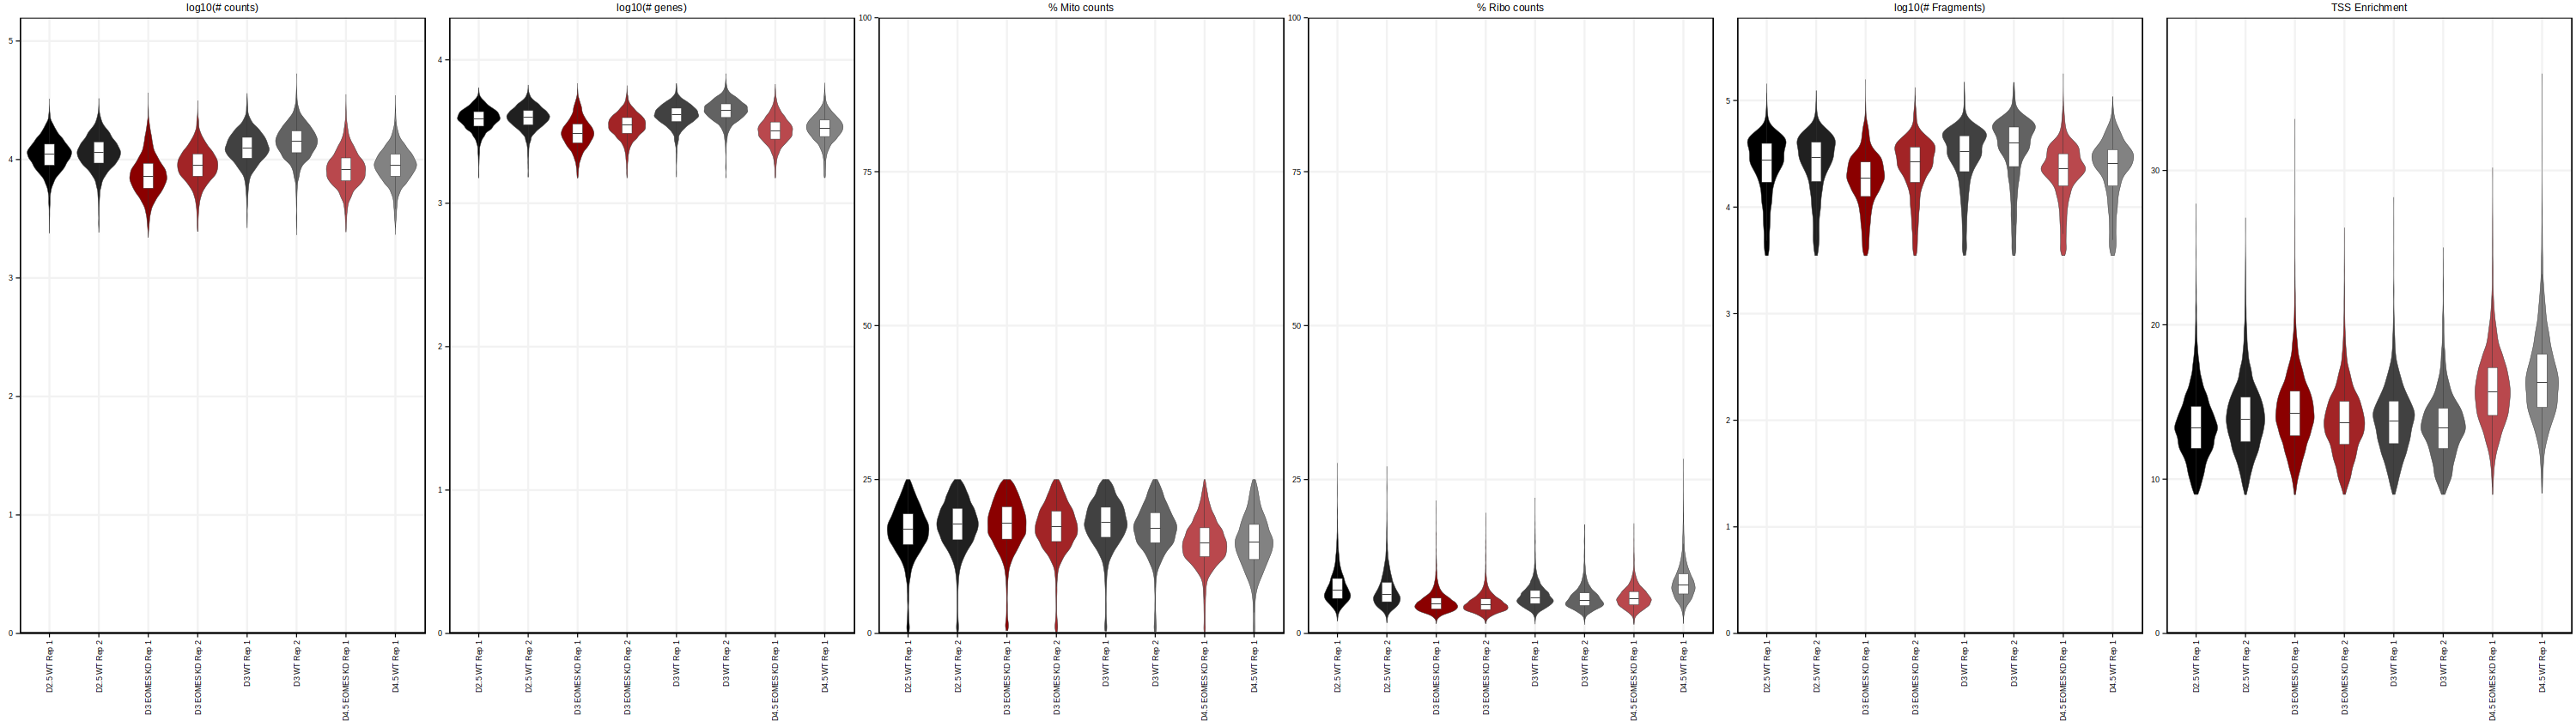

In [10]:
p1

In [11]:
library(ArchR)
addArchRThreads(12)
archr = loadArchRProject(io$archR.directory)


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

In [12]:
archr = archr[meta$cell]

In [13]:
tss.granges <- getTSS(archr)
tss.granges <- tss.granges[seqnames(tss.granges)%in%opts$chr]

data_tss.dt <- mclapply(opts$samples, function(i){
  plotTSSEnrichment(
    ArchRProj = archr[archr$Sample==i,], 
    groupBy = "Sample", 
    returnDF = TRUE,
    TSS = tss.granges
  ) %>% as.data.table %>% return
}, mc.cores=8) %>% rbindlist %>% 
  setnames("group","sample") %>% 
  melt(id.vars=c("sample","x"))

In [ ]:
data_fragmentsize.dt <-  mclapply(opts$samples, function(i){
  plotFragmentSizes(
    ArchRProj = archr[archr$Sample==i,], 
    groupBy = "Sample", 
    returnDF = TRUE
  ) %>% as.data.table %>% return
}, mc.cores=8) %>% rbindlist %>% setnames("group","sample")

In [ ]:
TSS = data_tss.dt %>% copy() %>%
    .[,sample_clean := sample_rename[match(sample, names(sample_rename))]] %>% 
    .[,sample_clean := factor(sample_clean, levels = sample_rename)] %>% 
    .[,genotype_clean := genotype_rename[match(sample, names(genotype_rename))]] %>% 
    .[,genotype_clean := factor(genotype_clean, levels = unique(genotype_rename))]

In [ ]:
FragmentSize = data_fragmentsize.dt %>% copy() %>%
    .[,sample_clean := sample_rename[match(sample, names(sample_rename))]] %>% 
    .[,sample_clean := factor(sample_clean, levels = sample_rename)] %>% 
    .[,genotype_clean := genotype_rename[match(sample, names(genotype_rename))]] %>% 
    .[,genotype_clean := factor(genotype_clean, levels = unique(genotype_rename))]

In [ ]:
theme_atac = theme + theme(legend.position = 'none', 
         strip.background = element_blank(),
         strip.text = element_text(size = 5),
         axis.title = element_text(size = 6, color = 'black'),
         )

p_atac_tssE = ggplot(TSS[variable == 'normValue'], aes(x, value, color = sample_clean)) + 
    geom_line(linewidth = 0.2) + 
    scale_color_manual(values = sample_colors) +
    xlab('Distance from TSS') + ylab('Enrichment score') + 
    facet_wrap(~genotype_clean) + 
    theme_atac

p_atac_fragments = ggplot(FragmentSize, aes(fragmentSize, fragmentPercent, color = sample_clean)) + 
    geom_line(linewidth = 0.2) + 
    scale_color_manual(values = sample_colors) +
    xlab('Fragment length') + ylab('% Fragments') + 
    facet_wrap(~genotype_clean) + 
    theme_atac

p2 = ggarrange(p_atac_tssE, p_atac_fragments, nrow = 1, align = 'hv', widths = c(1,1,0.25))
p2

In [ ]:
ggarrange(p1, p2 , ncol = 1)

In [ ]:
ggarrange(
    ggarrange(
        p_rna_reads, 
        p_rna_genes, 
        p_rna_mito, 
        p_rna_ribo, 
        nrow = 1, align = 'hv'),
    ggarrange(
        p_atac_frags, 
        p_atac_tss, 
        p_atac_tssE, 
        p_atac_fragments,
        nrow = 1, align = 'hv'),
    nrow = 2
)

In [ ]:
ggsave(file.path(io$basedir, 'results/manuscript//multiome_QC_metrics.pdf'), 
       plot = ggarrange(
            ggarrange(
                p_rna_reads, 
                p_rna_genes, 
                p_rna_mito, 
                p_rna_ribo, 
                nrow = 1, align = 'hv'),
            ggarrange(
                p_atac_frags, 
                p_atac_tss, 
                p_atac_tssE, 
                p_atac_fragments,
                nrow = 1, align = 'hv'),
            nrow = 2
        ),
       width = 150, 
       height = 100, 
       units = "mm")

In [ ]:
p1 = ggarrange(p_rna_reads, p_rna_genes, p_rna_mito, p_rna_ribo, p_atac_frags, p_atac_tss, nrow = 1, align = 'hv')
p2 = ggarrange(p_atac_tssE, p_atac_fragments, p_peak_stats, nrow = 1, align = 'hv', widths = c(1,1,0.25))


In [ ]:
ggarrange(ggarrange(p_rna_reads, p_rna_genes, p_rna_mito, p_rna_ribo, nrow = 1, align = 'hv' ),
          ggarrange(p_atac_frags, p_atac_tss, p_peak_stats, NULL, nrow = 1, align = 'hv'),
          ggarrange(p_atac_tssE, p_atac_fragments, nrow = 1, align = 'hv'),
          ncol = 1, align = 'hv')

# Export for GEO

In [14]:
getwd()

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code/Manuscript"

In [16]:
# Combine meta
meta_45 = fread('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/day_45_v2/d45_celltypes.txt.gz')
meta_253 = fread('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/day_253_v2/d253_celltypes.txt.gz')

In [17]:
colnames(meta_45)
colnames(meta_253)

[1] "cell"                      "orig.ident"               
 [3] "nCount_RNA"                "nFeature_RNA"             
 [5] "barcode"                   "sample"                   
 [7] "mitochondrial_percent_RNA" "ribosomal_percent_RNA"    
 [9] "alias"                     "day"                      
[11] "genotype"                  "pass_rnaQC"               
[13] "doublet_score"             "doublet_call"             
[15] "celltype"                  "celltype.score"           
[17] "closest.cell"              "day_celltype"             
[19] "celltype_genotype"         "TSSEnrichment_atac"       
[21] "ReadsInTSS_atac"           "PromoterRatio_atac"       
[23] "NucleosomeRatio_atac"      "nFrags_atac"              
[25] "BlacklistRatio_atac"       "pass_atacQC"              
[27] "RNA_snn_res.0.9"           "seurat_clusters"          
[29] "celltype_manual"

[1] "cell"                      "orig.ident"               
 [3] "nCount_RNA"                "nFeature_RNA"             
 [5] "barcode"                   "sample"                   
 [7] "mitochondrial_percent_RNA" "ribosomal_percent_RNA"    
 [9] "alias"                     "day"                      
[11] "genotype"                  "pass_rnaQC"               
[13] "doublet_score"             "doublet_call"             
[15] "celltype"                  "celltype.score"           
[17] "closest.cell"              "day_celltype"             
[19] "celltype_genotype"         "TSSEnrichment_atac"       
[21] "ReadsInTSS_atac"           "PromoterRatio_atac"       
[23] "NucleosomeRatio_atac"      "nFrags_atac"              
[25] "BlacklistRatio_atac"       "pass_atacQC"              
[27] "RNA_snn_res.0.1"           "seurat_clusters"          
[29] "celltype_manual"           "umap1"                    
[31] "umap2"                     "cluster"

In [24]:
ncol(meta_45)

[1] 29

In [33]:
meta_full = rbind(meta_253[, 1:29], meta_45, fill = TRUE) %>% 
    .[, genotype := gsub('Eomes_KO', 'Eomes KD', genotype)]

In [31]:
nrow(meta_full)

[1] 46547

In [34]:
table(meta_full$genotype)


Eomes KD       WT 
   24075    22472 

In [36]:
fwrite(meta_full, '/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/metadata.csv')

In [40]:
rna.sce <- load_SingleCellExperiment(io$rna.sce, normalise = TRUE, cells = meta_full$cell)

In [42]:
saveRDS(rna.sce, '/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/SingleCellExperiment.rds')

In [43]:
library(ArchR)
addArchRThreads(12)
archr = loadArchRProject(io$archR.directory)

Setting default number of Parallel threads to 12.

Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
       

In [46]:
archr = archr[meta_full$cell]

In [47]:
archr


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/processed/atac/archR 
samples(8): RBG43471 RBG43472 ... RBG43477 RBG43478
sampleColData names(1): ArrowFiles
cellColData names(38): Sample TSSEnrichment ... ReadsInPeaks FRIP
numberOfCells(1): 46547
medianTSS(1): 14.255
medianFrags(1): 25077

In [48]:
atac.sce = getMatrixFromProject(
  ArchRProj = archr,
  useMatrix = "PeakMatrix")

ArchR logging to : ArchRLogs/ArchR-getMatrixFromProject-8fa19229ddd9f-Date-2026-10-19_Time-21-19-39.log
If there is an issue, please report to github with logFile!

2026-10-19 21:20:00 : Organizing colData, 0.346 mins elapsed.

2026-10-19 21:20:00 : Organizing rowData, 0.352 mins elapsed.

2026-10-19 21:20:00 : Organizing rowRanges, 0.352 mins elapsed.

2026-10-19 21:20:00 : Organizing Assays (1 of 1), 0.352 mins elapsed.

2026-10-19 21:20:15 : Constructing SummarizedExperiment, 0.597 mins elapsed.

2026-10-19 21:20:31 : Finished Matrix Creation, 0.863 mins elapsed.



In [49]:
saveRDS(rna.sce, '/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/PeakMatrix.rds')